In [16]:
import numpy as np 
from netCDF4 import Dataset
import matplotlib.pyplot as plt
from datetime import datetime, timedelta

import cartopy.crs as ccrs                              
import cartopy.feature as cfeature                   
import cartopy.io.shapereader as shpreader

import warnings
warnings.filterwarnings("ignore")

from matplotlib.colors import LogNorm

In [17]:
path_ROA = "/work/scratch-nopw2/mendrika/mdg/roa"

year = "2022"
month = "02"
day = "14"
hour = "12"
minute = "00"

file_path = (
    f"{path_ROA}/{year}/{month}/"
    f"roa_{year}{month}{day}{hour}{minute}.npy"
)

data = np.load(file_path)

print(file_path)
print(data.shape)

/work/scratch-nopw2/mendrika/mdg/roa/2022/02/roa_202202141200.npy
(555, 555)


In [18]:
lons = np.load(
    "/home/users/mendrika/ASNIE/Cropping/roa_lons_mdg.npy"
)

lats = np.load(
    "/home/users/mendrika/ASNIE/Cropping/roa_lats_mdg.npy"
)

print("Data:", data.shape)
print("Lons:", lons.shape)
print("Lats:", lats.shape)

Data: (555, 555)
Lons: (555, 370)
Lats: (555, 370)


In [19]:
dlon = lons[0, 1] - lons[0, 0]

print("dlon:", dlon)

n_left = 92
n_right = 93

lon_1d = lons[0, :]

left = lon_1d[0] - dlon * np.arange(n_left, 0, -1)
right = lon_1d[-1] + dlon * np.arange(1, n_right + 1)

lon_square = np.concatenate([
    left,
    lon_1d,
    right
])

print(lon_square.shape)
print(lon_square[0], lon_square[-1])

dlon: 0.02701729106627937
(555,)
39.51909221902045 54.48667146974035


In [20]:
lat_1d = lats[:, 0]

lons_square, lats_square = np.meshgrid(
    lon_square,
    lat_1d
)

print(lons_square.shape)
print(lats_square.shape)
print(data.shape)

(555, 555)
(555, 555)
(555, 555)


In [21]:
from scipy.ndimage import zoom

OUTPUT_SHAPE = (128, 128)

zoom_factors = (
    OUTPUT_SHAPE[0] / lats_square.shape[0],
    OUTPUT_SHAPE[1] / lats_square.shape[1]
)

lats_128 = zoom(
    lats_square,
    zoom_factors,
    order=1
)

lons_128 = zoom(
    lons_square,
    zoom_factors,
    order=1
)

print("Lats 128:", lats_128.shape)
print("Lons 128:", lons_128.shape)

np.save(
    "/home/users/mendrika/ASNIE/Cropping/roa_lats_mdg_128.npy",
    lats_128.astype(np.float32)
)

np.save(
    "/home/users/mendrika/ASNIE/Cropping/roa_lons_mdg_128.npy",
    lons_128.astype(np.float32)
)

Lats 128: (128, 128)
Lons 128: (128, 128)


In [22]:
CONTEXT_LAT_MIN = -26
CONTEXT_LAT_MAX = -12
CONTEXT_LON_MIN = 40
CONTEXT_LON_MAX = 52

extent = (
    CONTEXT_LON_MIN,
    CONTEXT_LON_MAX,
    CONTEXT_LAT_MIN,
    CONTEXT_LAT_MAX,    
)

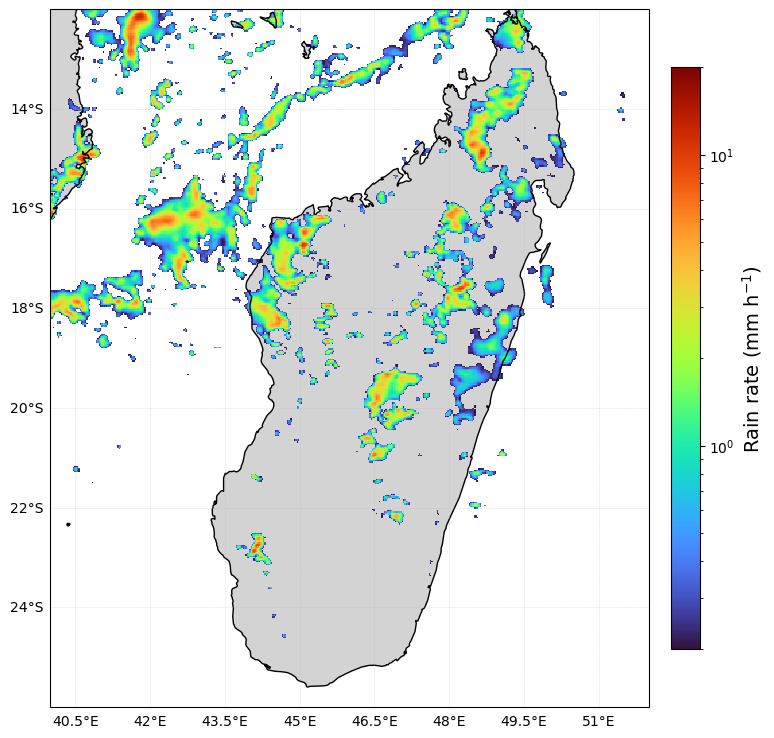

In [23]:
# Mask weak rain (stronger threshold)
roa_plot = np.ma.masked_less(data, 0.2)

fig = plt.figure(figsize=(8, 10))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent(extent, crs=ccrs.PlateCarree())

# Clean background
ax.add_feature(cfeature.LAND, facecolor="lightgrey", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="white", zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=1.0, zorder=2)
ax.add_feature(cfeature.BORDERS, linewidth=0.6, zorder=2)

# Gridlines
gl = ax.gridlines(draw_labels=True, linestyle="--", linewidth=0.4, alpha=0.4)
gl.top_labels = False
gl.right_labels = False

# Plot with log scaling (BIG improvement)
im = ax.pcolormesh(
    lon_square,
    lats_square,
    roa_plot,
    transform=ccrs.PlateCarree(),
    cmap="turbo",
    norm=LogNorm(vmin=0.2, vmax=20),
    zorder=1,
)

# Colorbar
cbar = plt.colorbar(im, ax=ax, pad=0.03, shrink=0.6)
cbar.set_label("Rain rate (mm h$^{-1}$)", fontsize=14)

# Styling
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.tight_layout()
plt.show()

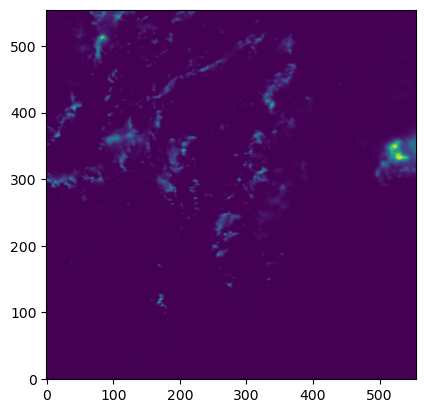

In [24]:
plt.imshow(data, origin="lower")
plt.show()

In [25]:
from scipy.ndimage import zoom

data_128 = zoom(
    data,
    (128 / 555, 128 / 555),
    order=1
)

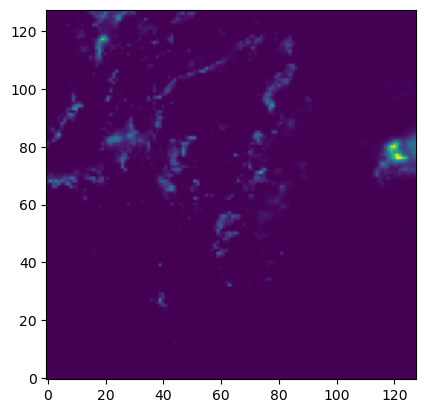

In [26]:
plt.imshow(data_128, origin="lower")
plt.show()

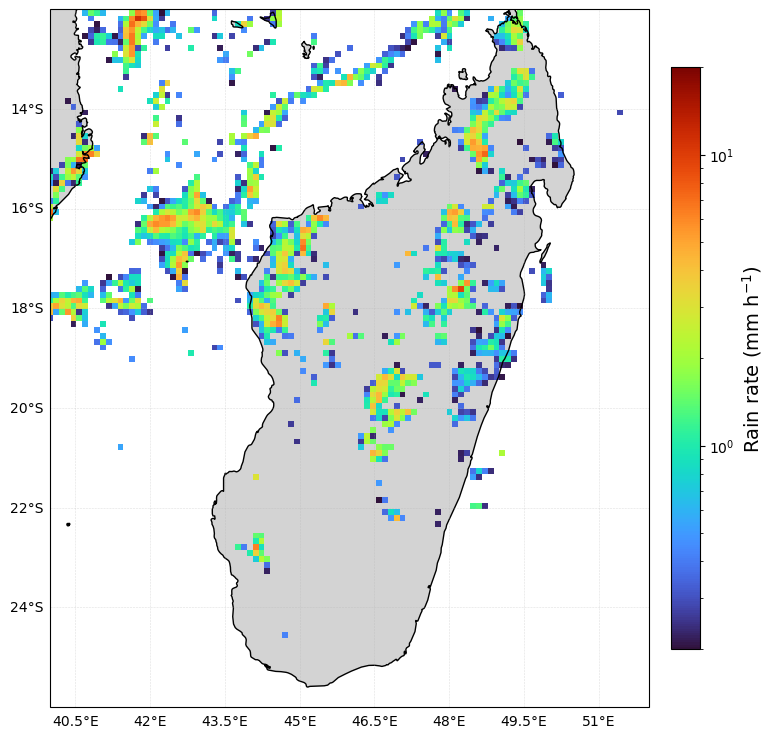

In [27]:
# Mask weak rain (stronger threshold)
roa_plot = np.ma.masked_less(data_128, 0.2)

fig = plt.figure(figsize=(8, 10))
ax = plt.axes(projection=ccrs.PlateCarree())

ax.set_extent(extent, crs=ccrs.PlateCarree())

# Clean background
ax.add_feature(cfeature.LAND, facecolor="lightgrey", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="white", zorder=0)
ax.add_feature(cfeature.COASTLINE, linewidth=1.0, zorder=2)
ax.add_feature(cfeature.BORDERS, linewidth=0.6, zorder=2)

# Gridlines
gl = ax.gridlines(draw_labels=True, linestyle="--", linewidth=0.4, alpha=0.4)
gl.top_labels = False
gl.right_labels = False

# Plot with log scaling (BIG improvement)
im = ax.pcolormesh(
    lons_128,
    lats_128,
    roa_plot,
    transform=ccrs.PlateCarree(),
    cmap="turbo",
    norm=LogNorm(vmin=0.2, vmax=20),
    zorder=1,
)

# Colorbar
cbar = plt.colorbar(im, ax=ax, pad=0.03, shrink=0.6)
cbar.set_label("Rain rate (mm h$^{-1}$)", fontsize=14)

# Styling
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)

plt.tight_layout()
plt.show()

# 

In [28]:
import os
import numpy as np
from datetime import timedelta
from scipy.ndimage import zoom

PATH_ROA = "/work/scratch-nopw2/mendrika/mdg/roa"

OUTPUT_SHAPE = (128, 128)

INPUT_HOURS = [-2, -1, 0]
TARGET_HOURS = [1, 2, 3]


def get_roa_path(time):
    return (
        f"{PATH_ROA}/{time:%Y}/{time:%m}/"
        f"roa_{time:%Y%m%d%H%M}.npy"
    )


def load_roa(time):
    file_path = get_roa_path(time)

    if not os.path.isfile(file_path):
        return None

    data = np.load(file_path)

    if data.ndim != 2:
        raise ValueError(
            f"Expected 2D ROA data, got shape {data.shape}: {file_path}"
        )

    zoom_factors = (
        OUTPUT_SHAPE[0] / data.shape[0],
        OUTPUT_SHAPE[1] / data.shape[1]
    )

    data = zoom(
        data,
        zoom_factors,
        order=1
    )

    return data.astype(np.float32)


def create_sample(t):
    input_times = [
        t + timedelta(hours=h)
        for h in INPUT_HOURS
    ]

    target_times = [
        t + timedelta(hours=h)
        for h in TARGET_HOURS
    ]

    inputs = [
        load_roa(time)
        for time in input_times
    ]

    targets = [
        load_roa(time)
        for time in target_times
    ]

    if any(data is None for data in inputs + targets):
        return None

    X = np.stack(inputs, axis=0)
    y = np.stack(targets, axis=0)

    return X, y

In [29]:
from datetime import datetime

t = datetime(2023, 2, 10, 15, 0)

sample = create_sample(t)

if sample is not None:
    X, y = sample

    print("X:", X.shape)
    print("y:", y.shape)

X: (3, 128, 128)
y: (3, 128, 128)


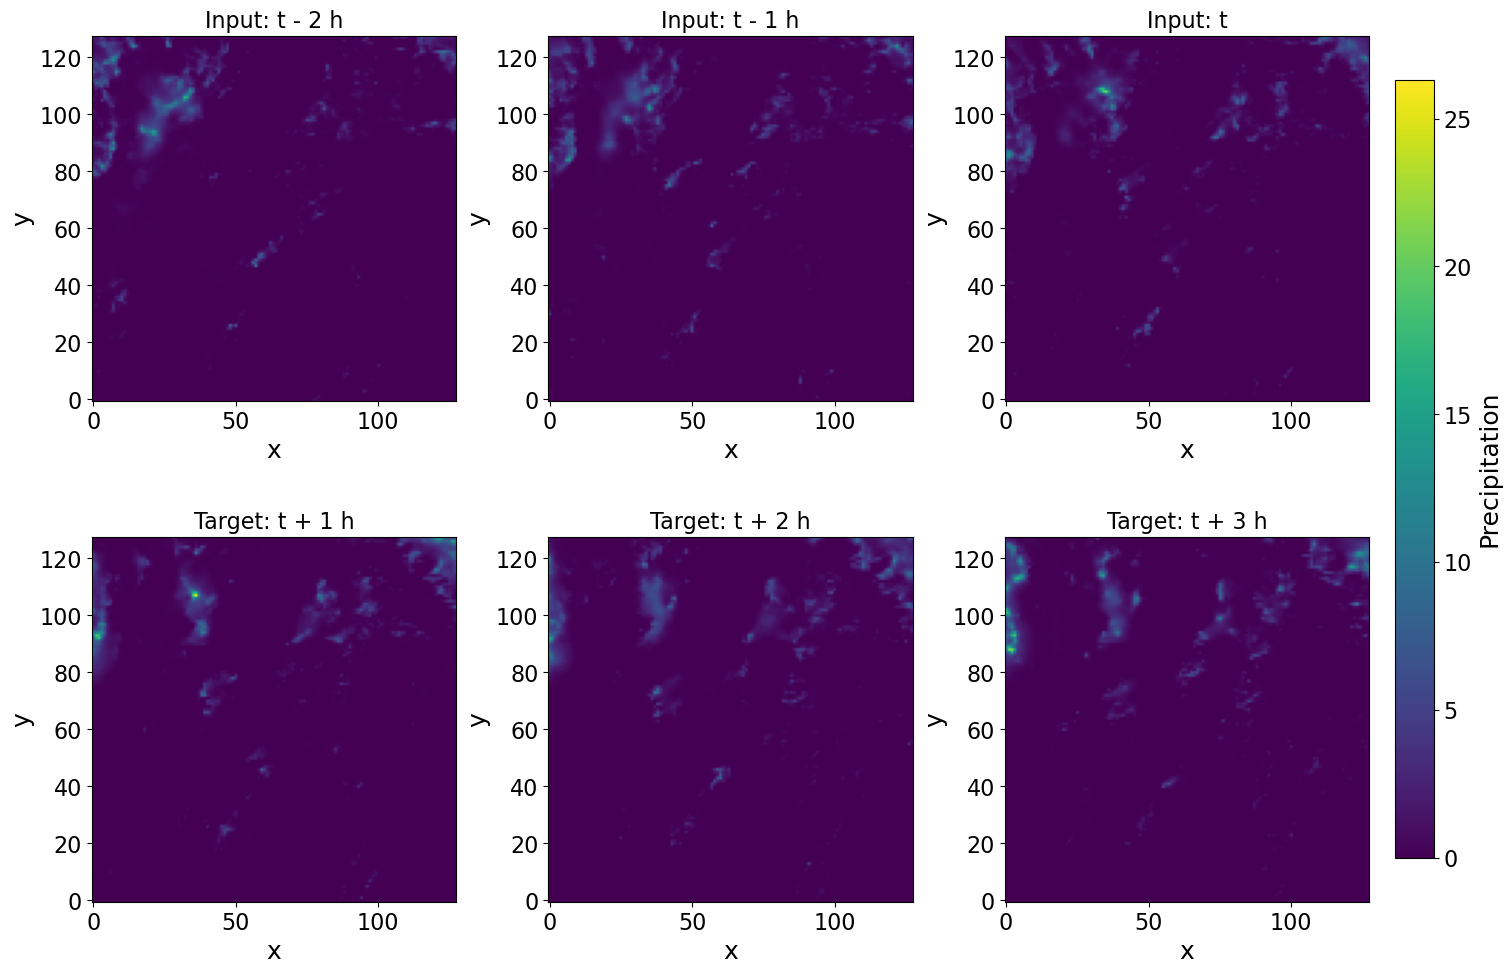

In [30]:
import matplotlib.pyplot as plt
import numpy as np

frames = [
    X[0],
    X[1],
    X[2],
    y[0],
    y[1],
    y[2]
]

titles = [
    "Input: t - 2 h",
    "Input: t - 1 h",
    "Input: t",
    "Target: t + 1 h",
    "Target: t + 2 h",
    "Target: t + 3 h"
]

vmin = 0
vmax = np.nanmax(frames)

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 10),
    constrained_layout=True
)

for ax, frame, title in zip(axes.flat, frames, titles):
    im = ax.imshow(
        frame,
        origin="lower",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(title, fontsize=16)
    ax.set_xlabel("x", fontsize=18)
    ax.set_ylabel("y", fontsize=18)
    ax.tick_params(axis="both", labelsize=16)
    ax.grid(False)

cbar = fig.colorbar(
    im,
    ax=axes,
    shrink=0.8,
    pad=0.02
)

cbar.set_label("Precipitation", fontsize=18)
cbar.ax.tick_params(labelsize=16)

plt.show()

In [31]:
train = np.load(
    "/work/scratch-nopw2/mendrika/mdg/hackathon/train.npz"
)

test = np.load(
    "/work/scratch-nopw2/mendrika/mdg/hackathon/test.npz"
)

targets = np.load(
    "/work/scratch-nopw2/mendrika/mdg/hackathon/test_targets_private.npz"
)

print("Train X:", train["X"].shape)
print("Train y:", train["y"].shape)

print("Test X:", test["X"].shape)
print("Test y:", targets["y"].shape)

print("Train times:", train["times"].shape)
print("Test times:", test["times"].shape)

print("Lats:", train["lats"].shape)
print("Lons:", train["lons"].shape)

Train X: (10862, 3, 128, 128)
Train y: (10862, 3, 128, 128)
Test X: (2920, 3, 128, 128)
Test y: (2920, 3, 128, 128)
Train times: (10862,)
Test times: (2920,)
Lats: (128, 128)
Lons: (128, 128)
